# Price changes and renewals: measuring the real impact

Consumer security software is a subscription business, and the **renewal** is the most price-sensitive moment. This notebook simulates a renewal-price increase in some markets and shows how to measure its impact properly.

**Key formulas**

| What | Formula |
|---|---|
| Renewal revenue | $N \cdot r \cdot p$ — subscriptions due × renewal rate × price |
| Short-term break-even renewal rate | $r_1^{*} = r_0 \cdot \dfrac{p_0}{p_1}$ |
| Future value of a renewal cohort | $V = N \cdot p \cdot m \cdot \dfrac{r}{1-r}$ (all future renewals, constant rate) |
| Long-term break-even renewal rate | $r_1^{*}$ such that $p_1 \dfrac{r_1}{1-r_1} = p_0 \dfrac{r_0}{1-r_0}$ |
| Difference-in-differences | $(\bar r_{T,after} - \bar r_{T,before}) - (\bar r_{C,after} - \bar r_{C,before})$ |
| Renewal elasticity | $\%\Delta r \,/\, \%\Delta p$ |

Sections:
1. The slide example: +2.7% revenue, but 4,000 customers lost
2. Simulate customer-level renewal data
3. Explore: renewal rate over time
4. Naive before/after vs difference-in-differences
5. Who reacts most: effects by segment
6. Refunds after the increase
7. Revenue today vs value tomorrow
8. Break-even renewal rates
9. Takeaways

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 10.5,
})

C = {"treated": "#B8166F", "control": "#5B21B6", "base": "#3F3A52",
     "good": "#17784F", "bad": "#B8166F", "neutral": "#8A8F98", "accent": "#D97706"}
pct = mticker.PercentFormatter(1, decimals=0)
pct1 = mticker.PercentFormatter(1, decimals=1)
eur_m = mticker.FuncFormatter(lambda v, _: f"€{v/1e6:,.1f}M")

## 1. The slide example

100,000 subscriptions are due for renewal at €50 with a 60% renewal rate. The renewal price rises 10% and the renewal rate drops to 56%.

In [2]:
def renewal_economics(n, r, p, margin=0.85):
    revenue = n * r * p                       # cash from this renewal
    future_value = n * p * margin * r / (1 - r)   # this renewal + all later ones (constant r)
    return pd.Series({"renewed": n * r, "renewal revenue": revenue, "future value": future_value})

before = renewal_economics(100_000, 0.60, 50)
after = renewal_economics(100_000, 0.56, 55)
ex = pd.DataFrame({"before": before, "after +10%": after})
ex["change"] = ex["after +10%"] - ex["before"]
ex["change %"] = ex["change"] / ex["before"]
ex

,before,after +10%,change,change %
renewed,"60,000.000","56,000.000","-4,000.000",-0.067
renewal revenue,"3,000,000.000","3,080,000.000","80,000.000",0.027
future value,"6,375,000.000","5,950,000.000","-425,000.000",-0.067


Renewal revenue grows **+2.7%**, but 4,000 fewer customers renew — and they won't renew next year either. Counting all future renewals, the cohort's value **falls by about 6.7%**. A price increase can win this year and lose over the customer lifetime.

## 2. Simulate customer-level renewal data

Built-in assumptions, so we know what the analysis should find:

- 24 months of renewals (Jan 2025 – Dec 2026). From **Jan 2026** the renewal price rises **+10%** in **DE, FR, UK** (treated); **US, ES, IT** keep prices (control).
- A **common upward trend** of about +2 pp in 2026 (product improvements, better reminders) — it hits all markets, so a naive before/after comparison is biased.
- True effect of the increase: about **−4 pp** on renewal rate on average; stronger for **first renewals** and customers **without auto-renewal**, weaker for loyal auto-renewing customers.
- Refunds among renewed customers rise from about 3% to 4.5% after the increase.

In [3]:
rng = np.random.default_rng(42)

markets = pd.DataFrame({
    "market": ["DE", "FR", "UK", "US", "ES", "IT"],
    "group": ["treated"] * 3 + ["control"] * 3,
    "base_logit": [0.35, 0.20, 0.30, 0.25, 0.10, 0.15],
    "monthly_due": [1700, 1300, 1400, 2600, 1000, 1100],
})
tiers = pd.DataFrame({"tier": ["Standard", "Plus", "Premium"],
                      "price": [40.0, 55.0, 70.0], "share": [0.45, 0.35, 0.20], "tier_logit": [-0.10, 0.0, 0.15]})
months = pd.period_range("2025-01", "2026-12", freq="M")
CHANGE = pd.Period("2026-01", "M")
PRICE_UP = 0.10

rows = []
for _, m in markets.iterrows():
    for mo in months:
        n = rng.poisson(m["monthly_due"])
        d = pd.DataFrame({
            "market": m["market"], "group": m["group"], "month": mo,
            "tier": rng.choice(tiers["tier"], n, p=tiers["share"]),
            "first_renewal": rng.random(n) < 0.45,
            "auto_renew": rng.random(n) < 0.55,
        })
        d["base_logit"] = m["base_logit"]
        rows.append(d)
subs = pd.concat(rows, ignore_index=True)
subs = subs.merge(tiers[["tier", "price", "tier_logit"]], on="tier")

after = subs["month"] >= CHANGE
treated_after = (subs["group"] == "treated") & after
season = 0.08 * np.sin(2 * np.pi * subs["month"].dt.month / 12)

logit = (subs["base_logit"] + subs["tier_logit"] + season
         - 0.75 * subs["first_renewal"] + 0.95 * subs["auto_renew"]
         + 0.09 * after)                                            # common trend (+~2 pp)
# price-increase effect: stronger for first renewals and manual renewals
effect = -(0.06 + 0.10 * subs["first_renewal"] + 0.10 * ~subs["auto_renew"])
logit = logit + np.where(treated_after, effect, 0)

subs["renewal_price"] = np.where(treated_after, subs["price"] * (1 + PRICE_UP), subs["price"])
subs["renewed"] = (rng.random(len(subs)) < 1 / (1 + np.exp(-logit))).astype(int)
refund_p = np.where(treated_after, 0.045, 0.03)
subs["refunded"] = ((rng.random(len(subs)) < refund_p) & (subs["renewed"] == 1)).astype(int)
subs["net_revenue"] = subs["renewed"] * subs["renewal_price"] * (1 - subs["refunded"])
subs["period"] = np.where(after, "after", "before")

subs = subs[["market", "group", "month", "period", "tier", "first_renewal", "auto_renew",
             "price", "renewal_price", "renewed", "refunded", "net_revenue"]]
print(f"{len(subs):,} subscriptions due for renewal")
subs.head()

218,419 subscriptions due for renewal


,market,group,month,period,tier,first_renewal,auto_renew,price,renewal_price,renewed,refunded,net_revenue
0,DE,treated,2025-01,before,Premium,True,False,70.000,70.000,1,0,70.000
1,DE,treated,2025-01,before,Plus,False,True,55.000,55.000,1,0,55.000
2,DE,treated,2025-01,before,Standard,False,False,40.000,40.000,0,0,0.000
3,DE,treated,2025-01,before,Premium,True,True,70.000,70.000,1,0,70.000
4,DE,treated,2025-01,before,Plus,True,False,55.000,55.000,1,0,55.000


## 3. Explore: renewal rate over time

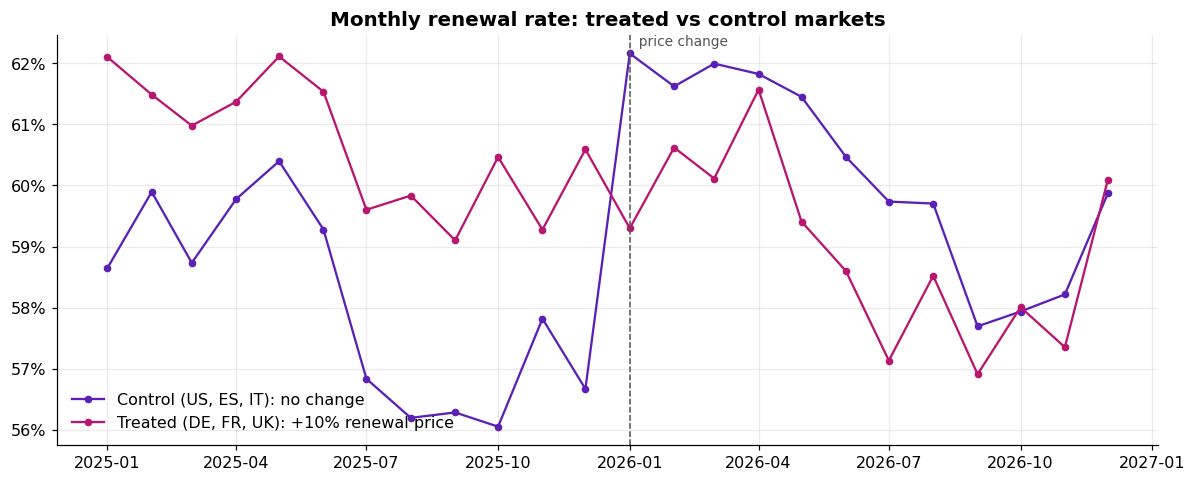

In [4]:
monthly = subs.groupby(["month", "group"])["renewed"].mean().unstack()
x = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(x, monthly["control"], marker="o", ms=4, color=C["control"], label="Control (US, ES, IT): no change")
ax.plot(x, monthly["treated"], marker="o", ms=4, color=C["treated"], label="Treated (DE, FR, UK): +10% renewal price")
ax.axvline(CHANGE.to_timestamp(), color="#555", ls="--", lw=1)
ax.text(CHANGE.to_timestamp(), ax.get_ylim()[1], "  price change", va="top", fontsize=9, color="#555")
ax.yaxis.set_major_formatter(pct)
ax.set_title("Monthly renewal rate: treated vs control markets")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); plt.show()

Before the change, the two lines move **in parallel** — the key assumption of difference-in-differences. After January 2026 the control markets go *up* (the common trend), while the treated markets dip: the price increase more than cancelled an improvement they would otherwise have had.

## 4. Naive before/after vs difference-in-differences

In [5]:
cell = subs.groupby(["group", "period"])["renewed"].agg(rate="mean", n="size").unstack("period")
rate = cell["rate"][["before", "after"]]
n = cell["n"][["before", "after"]]

naive = rate.loc["treated", "after"] - rate.loc["treated", "before"]
control_change = rate.loc["control", "after"] - rate.loc["control", "before"]
did = naive - control_change
se = np.sqrt(sum(rate.loc[g, p] * (1 - rate.loc[g, p]) / n.loc[g, p]
                 for g in ["treated", "control"] for p in ["before", "after"]))

print(f"Naive before/after in treated markets: {naive * 100:+.2f} pp")
print(f"Change in control markets (trend):     {control_change * 100:+.2f} pp")
print(f"Difference-in-differences effect:      {did * 100:+.2f} pp  (95% CI {(did - 1.96*se) * 100:+.2f} … {(did + 1.96*se) * 100:+.2f} pp)")
print(f"Implied renewal elasticity:            {(did / rate.loc['treated', 'before']) / PRICE_UP:.2f}")
rate

Naive before/after in treated markets: -1.74 pp
Change in control markets (trend):     +2.18 pp
Difference-in-differences effect:      -3.92 pp  (95% CI -4.74 … -3.10 pp)
Implied renewal elasticity:            -0.65


period,before,after
group,,
control,0.580,0.602
treated,0.607,0.590


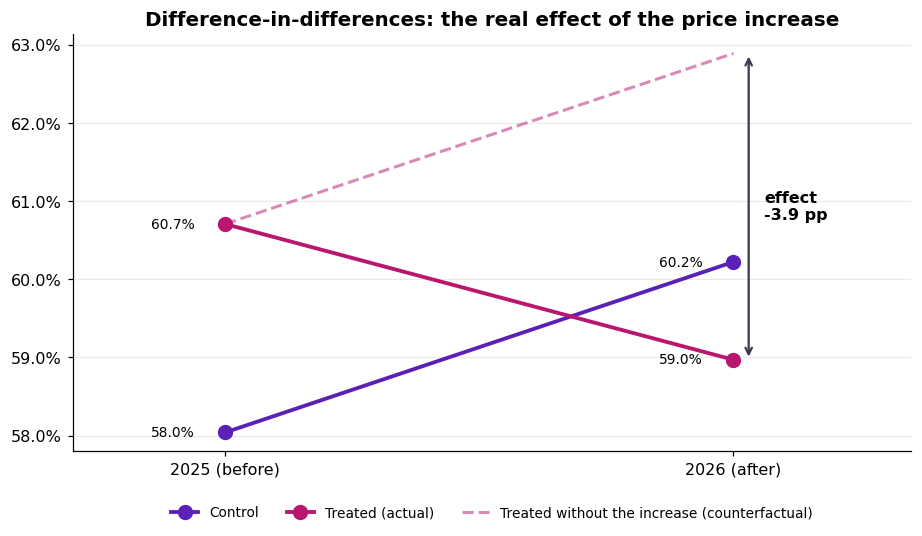

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5))
xs = [0, 1]
ax.plot(xs, rate.loc["control"], marker="o", ms=9, lw=2.5, color=C["control"], label="Control")
ax.plot(xs, rate.loc["treated"], marker="o", ms=9, lw=2.5, color=C["treated"], label="Treated (actual)")
cf = rate.loc["treated", "before"] + control_change
ax.plot(xs, [rate.loc["treated", "before"], cf], ls="--", lw=2, color=C["treated"], alpha=0.5,
        label="Treated without the increase (counterfactual)")
ax.annotate("", xy=(1.03, rate.loc["treated", "after"]), xytext=(1.03, cf),
            arrowprops=dict(arrowstyle="<->", color=C["base"], lw=1.5))
ax.text(1.06, (cf + rate.loc["treated", "after"]) / 2, f"effect\n{did * 100:+.1f} pp", va="center", fontweight="bold")
for g in ["control", "treated"]:
    for i, p in enumerate(["before", "after"]):
        ax.text(i - 0.06, rate.loc[g, p], f"{rate.loc[g, p]:.1%}", ha="right", va="center", fontsize=9)
ax.set_xticks(xs, ["2025 (before)", "2026 (after)"]); ax.set_xlim(-0.3, 1.35)
ax.yaxis.set_major_formatter(pct1)
ax.set_title("Difference-in-differences: the real effect of the price increase")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9)
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

The naive comparison shows only a small drop. That understates the damage: without the increase, the treated markets would have followed the control trend upward. The **difference-in-differences** estimate recovers the true effect of roughly −4 pp — more than twice the naive number.

*Assumption to state in an interview:* treated and control markets would have moved in parallel without the change (check the pre-period chart and run placebo tests on earlier months).

## 5. Who reacts most: effects by segment

In [7]:
def did_effect(d):
    r = d.groupby(["group", "period"])["renewed"].agg(["mean", "size"])
    m, k = r["mean"], r["size"]
    eff = (m["treated", "after"] - m["treated", "before"]) - (m["control", "after"] - m["control", "before"])
    se = np.sqrt(sum(m[i] * (1 - m[i]) / k[i] for i in m.index))
    base = m["treated", "before"]
    return pd.Series({"effect_pp": eff, "ci_low": eff - 1.96 * se, "ci_high": eff + 1.96 * se,
                      "base_rate": base, "elasticity": eff / base / PRICE_UP, "n": int(k.sum())})

segments = {
    "First renewal": subs["first_renewal"],
    "Later renewals": ~subs["first_renewal"],
    "Manual renewal": ~subs["auto_renew"],
    "Auto-renewal on": subs["auto_renew"],
    "Standard": subs["tier"] == "Standard",
    "Plus": subs["tier"] == "Plus",
    "Premium": subs["tier"] == "Premium",
}
seg = pd.DataFrame({name: did_effect(subs[mask]) for name, mask in segments.items()}).T
seg

,effect_pp,ci_low,ci_high,base_rate,elasticity,n
First renewal,-0.059,-0.071,-0.046,0.515,-1.145,"98,287.000"
Later renewals,-0.026,-0.036,-0.015,0.683,-0.374,"120,132.000"
Manual renewal,-0.050,-0.062,-0.037,0.488,-1.018,"98,107.000"
Auto-renewal on,-0.031,-0.041,-0.020,0.706,-0.435,"120,312.000"
Standard,-0.039,-0.051,-0.026,0.588,-0.658,"98,500.000"
Plus,-0.040,-0.054,-0.026,0.610,-0.652,"76,050.000"
Premium,-0.039,-0.057,-0.021,0.644,-0.605,"43,869.000"


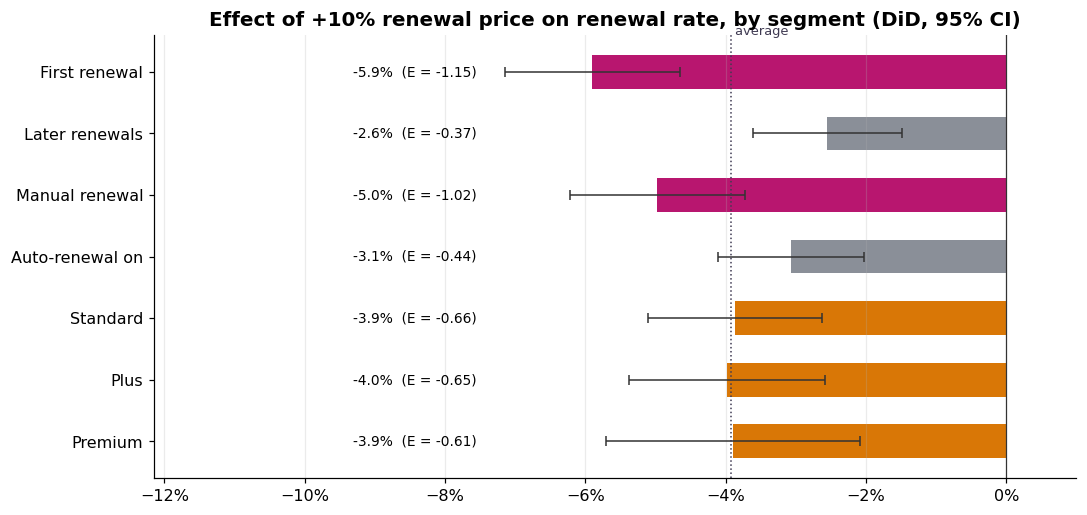

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(seg))[::-1]
colors = [C["bad"] if v < did * 1.2 else C["neutral"] if v > did * 0.8 else C["accent"] for v in seg["effect_pp"]]
ax.barh(y, seg["effect_pp"], color=colors, height=0.55)
ax.errorbar(seg["effect_pp"], y, xerr=[seg["effect_pp"] - seg["ci_low"], seg["ci_high"] - seg["effect_pp"]],
            fmt="none", ecolor="#333", capsize=3, lw=1)
for yi, (e, el) in zip(y, zip(seg["effect_pp"], seg["elasticity"])):
    ax.text(seg["ci_low"].min() - 0.004, yi, f"{e:+.1%}  (E = {el:.2f})", va="center", ha="right", fontsize=9)
ax.axvline(0, color="#333", lw=0.8)
ax.axvline(did, color=C["base"], lw=1, ls=":")
ax.text(did, len(seg) - 0.4, " average", fontsize=8.5, color=C["base"])
ax.set_yticks(y, seg.index)
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(seg["ci_low"].min() - 0.05, 0.01)
ax.set_title("Effect of +10% renewal price on renewal rate, by segment (DiD, 95% CI)")
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

First-time renewers and customers who renew manually react much more strongly — they actively decide at the new price. Loyal auto-renewing customers barely react. **Pricing implication:** consider protecting the first renewal (smaller step-up, loyalty offer) while applying increases to later renewals.

## 6. Refunds after the increase

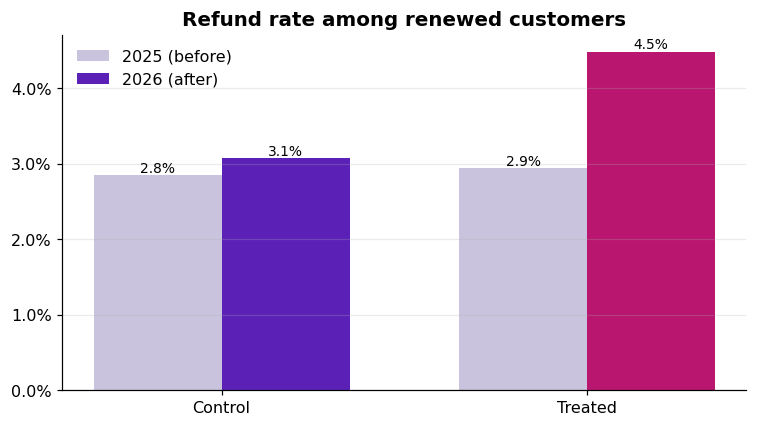

In [9]:
ref = subs[subs["renewed"] == 1].groupby(["group", "period"])["refunded"].mean().unstack()[["before", "after"]]
fig, ax = plt.subplots(figsize=(7, 4))
xx = np.arange(2); w = 0.35
ax.bar(xx - w/2, ref["before"], w, label="2025 (before)", color="#C9C3DD")
ax.bar(xx + w/2, ref["after"], w, label="2026 (after)", color=[C["control"], C["treated"]])
for i, g in enumerate(ref.index):
    ax.text(i - w/2, ref.loc[g, "before"], f"{ref.loc[g, 'before']:.1%}", ha="center", va="bottom", fontsize=9)
    ax.text(i + w/2, ref.loc[g, "after"], f"{ref.loc[g, 'after']:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(xx, [g.capitalize() for g in ref.index]); ax.yaxis.set_major_formatter(pct1)
ax.set_title("Refund rate among renewed customers"); ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

Refunds are the hidden cost of auto-renewal price jumps: customers notice the higher charge after it happens. Always measure **net** revenue after refunds — and watch complaints and chargebacks too.

## 7. Revenue today vs value tomorrow

Compare 2026 in the treated markets with the **counterfactual** — what would have happened without the increase (old price, renewal rate following the control trend, old refund rate).

In [10]:
t26 = subs[(subs["group"] == "treated") & (subs["period"] == "after")]
N = len(t26)
avg_old_price = t26["price"].mean()
r_actual = t26["renewed"].mean()
r_cf = r_actual - did                                   # counterfactual renewal rate
ref_actual = t26.loc[t26["renewed"] == 1, "refunded"].mean()
ref_cf = ref.loc["control", "after"]                    # refunds as in control markets
MARGIN = 0.85

def scenario(r, p, refund):
    net_price = p * (1 - refund)
    return pd.Series({
        "customers renewed": N * r,
        "net renewal revenue": N * r * net_price,
        "future value": N * net_price * MARGIN * r / (1 - r),
    })

comp = pd.DataFrame({
    "without increase": scenario(r_cf, avg_old_price, ref_cf),
    "with +10%": scenario(r_actual, avg_old_price * (1 + PRICE_UP), ref_actual),
})
comp["change"] = comp["with +10%"] - comp["without increase"]
comp["change %"] = comp["change"] / comp["without increase"]
comp

,without increase,with +10%,change,change %
customers renewed,"33,115.790","31,052.000","-2,063.790",-0.062
net renewal revenue,"1,644,759.219","1,671,806.006","27,046.787",0.016
future value,"3,767,262.717","3,463,431.869","-303,830.848",-0.081


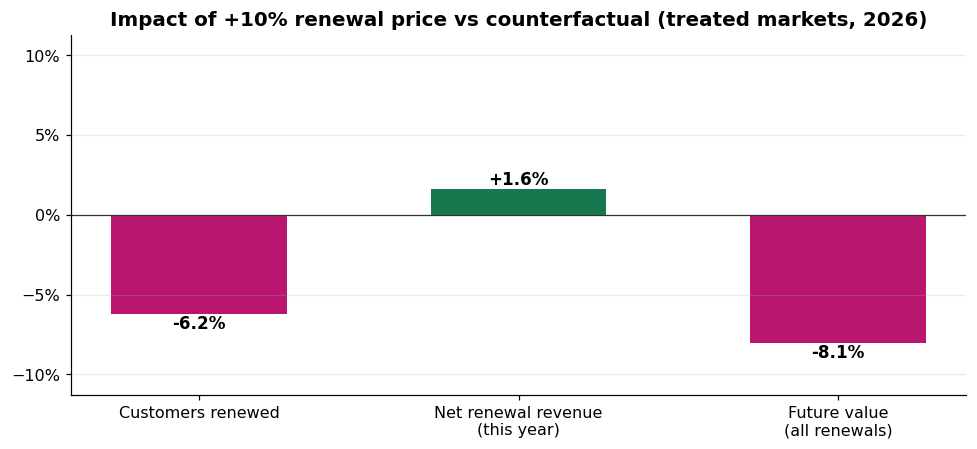

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = ["Customers renewed", "Net renewal revenue\n(this year)", "Future value\n(all renewals)"]
vals = comp["change %"].values
cols = [C["good"] if v > 0 else C["bad"] for v in vals]
bars = ax.bar(labels, vals, color=cols, width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:+.1%}", ha="center",
            va="bottom" if v > 0 else "top", fontweight="bold", fontsize=11)
ax.axhline(0, color="#333", lw=0.8)
ax.yaxis.set_major_formatter(pct)
lim = max(abs(vals)) * 1.4
ax.set_ylim(-lim, lim)
ax.set_title("Impact of +10% renewal price vs counterfactual (treated markets, 2026)")
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

This year's net renewal revenue goes up, but fewer customers stay and the cohort's future value is lower. Whether the increase is a "win" depends on which horizon the business optimises — and that should be agreed before the decision, not after.

## 8. Break-even renewal rates

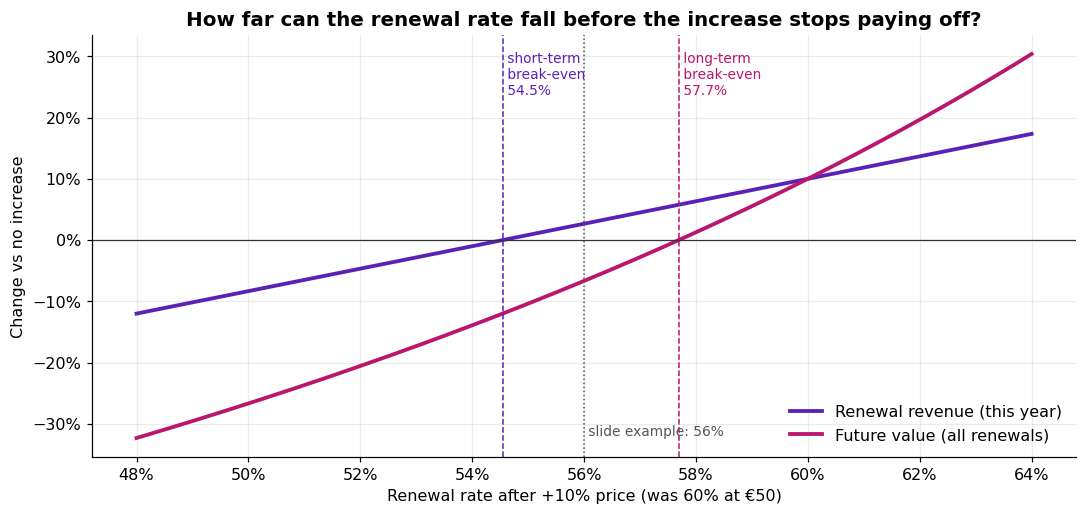

Short-term break-even: renewal rate may fall to 54.5% (-5.5 pp)
Long-term break-even:  renewal rate may fall only to 57.7% (-2.3 pp)


In [12]:
r0, p0, p1 = 0.60, 50.0, 55.0
v0 = p0 * r0 / (1 - r0)
be_short = r0 * p0 / p1                       # same renewal revenue
be_long = v0 / (p1 + v0)                      # same future value: p1 r / (1 - r) = v0

rs = np.linspace(0.48, 0.64, 200)
rev_change = (rs * p1) / (r0 * p0) - 1
val_change = (p1 * rs / (1 - rs)) / v0 - 1

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(rs, rev_change, lw=2.5, color=C["control"], label="Renewal revenue (this year)")
ax.plot(rs, val_change, lw=2.5, color=C["treated"], label="Future value (all renewals)")
ax.axhline(0, color="#333", lw=0.8)
for be, col, name in [(be_short, C["control"], "short-term"), (be_long, C["treated"], "long-term")]:
    ax.axvline(be, color=col, ls="--", lw=1)
    ax.text(be, ax.get_ylim()[1] * 0.92, f" {name}\n break-even\n {be:.1%}", color=col, fontsize=9, va="top")
ax.axvline(0.56, color="#555", ls=":", lw=1)
ax.text(0.56, ax.get_ylim()[0] * 0.9, " slide example: 56%", fontsize=9, color="#555")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Renewal rate after +10% price (was 60% at €50)")
ax.set_ylabel("Change vs no increase")
ax.set_title("How far can the renewal rate fall before the increase stops paying off?")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

print(f"Short-term break-even: renewal rate may fall to {be_short:.1%} ({(be_short - r0) * 100:+.1f} pp)")
print(f"Long-term break-even:  renewal rate may fall only to {be_long:.1%} ({(be_long - r0) * 100:+.1f} pp)")

The **long-term break-even is stricter**: with a 10% increase from a 60% base, the renewal rate may drop to about 54.5% before this year's revenue suffers, but only to about 57.7% before lifetime value suffers. In the slide example (56%), the increase wins short-term and loses long-term.

## 9. Takeaways

- Judge a renewal-price increase on **net** revenue after refunds and on **future value**, not only this year's renewal revenue.
- Use a **control group** (control markets, or a pre-change cohort) — naive before/after comparisons are biased by trends and seasonality. Difference-in-differences is a simple, defensible method; state the parallel-trends assumption.
- Effects are **heterogeneous**: first renewals and manual renewers react most. Segment-specific pricing (or protecting the first renewal) can capture most of the revenue with less churn.
- Compute **break-even renewal rates** before the decision: they turn "will customers leave?" into a concrete threshold the business can agree on.
- Measure over the **full renewal cycle**: refunds, complaints and second-year churn appear months later.

**Try it yourself:** change `PRICE_UP`, the `effect` coefficients or the common trend (`0.09 * after`) in section 2 and rerun to see how the estimates and break-even picture change.